# Volatility Band Width: Estimating and Backtesting Volatility Bands for the S&P 500
### K. Mohamed Harith
**Erdős Institute -- Quantitative Finance Bootcamp, Fall 2026** · [GitHub repository](https://github.com/Harry140896/Volatility-band-width)

**Question.** Can volatility models give reliable 95% bands for the S&P 500's next-day return? And if so, how should volatility be estimated to make them more reliable?

This notebook builds 95% bands from four volatility models: constant-volatility GBM, rolling-window GBM, the Exponentially Weighted Moving Average (EWMA) and GARCH(1,1) (Generalised Autoregressive Conditional Heteroskedasticity, with one lag each of squared returns and of variance). It has three parts:
1. **Building the bands:** the four models, each calibrated on 2005–2017.
2. **Backtesting:** recording when each model's band is missed on 2018–2026.
3. **Testing the misses:** Kupiec's test (are there 5% misses?) and Christoffersen's test (are the misses independent?), followed by conclusions.

**About the data.** We use daily closing prices of the S&P 500 index (Yahoo Finance ticker ^GSPC) from January 2005 to the 3rd November 2026, downloaded with `yfinance` (adjusted for splits and dividends where relevant) and saved to `data/gspc.csv` so that every run uses the same data. We work with daily log returns, $r_t = \ln(P_t / P_{t-1})$.

The data is split chronologically:
- **Calibration (fit) period: 2005–2017**, about 3,270 trading days, including the 2008 financial crisis;
- **Test period: 2018–present**, about 2,220 trading days, including the February 2018 volatility spike, the COVID-19 crash of March 2020, the 2022 bear market and the April 2025 sell-off.

Both periods contain a major crisis, so the models learn from one crisis and are tested on others; both also contain calm years. All model settings are chosen on the fit period only. The S&P 500 is a price index and excludes *dividends*; these are spread across many companies and days, so they barely affect daily volatility.

The following code cell contains all the required imports for running this notebook.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import norm,chi2
import seaborn as sns
import matplotlib.pyplot as plt
import yfinance as yf
from pathlib import Path
from matplotlib.ticker import PercentFormatter
from arch import arch_model
from scipy.special import xlogy  #For Kupiec Test

import warnings
warnings.filterwarnings("ignore", message=".*inplace keyword.*")
print(np.__version__)
print(yf.__version__)
print(pd.__version__)


2.5.4
1.7.0
3.1.0


We fix the random seed, download the S&P 500 data once (or load it from `data/gspc.csv` if it has already been saved), compute daily log returns, and split them into the calibration period (2005–2017) and the test period (2018 onwards).

In [2]:
#Setting the seed for reproducible results

SEED = 44
rng = np.random.default_rng(SEED)


# The folders set up
DATA_DIR = Path("data")
CSV_PATH = DATA_DIR/ "gspc.csv"


## Data downloading only if data does not exist. 
DATA_DIR.mkdir(exist_ok=True)
if not CSV_PATH.exists():
    df  = yf.Ticker("^GSPC").history(start = '2005-01-01', auto_adjust = True)
    df.index = df.index.tz_localize(None)
    df.to_csv(CSV_PATH)
    print(f'Downloaded and saved the CSV file in {CSV_PATH}')
else:
    df=pd.read_csv(CSV_PATH,index_col='Date',parse_dates=True)


## Loading the Close Price for the S&P500 Data
close = df['Close']  

# Log Returns Series
log_returns = np.log(close).diff().dropna()

#Extracting data for calibration and testing
fit_log_returns=log_returns['2005':'2017']
test_log_returns = log_returns['2018':]


## 1. Motivation: constant volatility and its band

### The GBM model
Under Geometric Brownian Motion, the log return of a stock over a short interval $\Delta t$ (in years) is normally distributed:
$$
r_t = \ln\frac{S_t}{S_{t-\Delta t}} = \left(\mu - \tfrac{\sigma^2}{2}\right)\Delta t + \sigma\sqrt{\Delta t}\; X, \qquad X \sim N(0,1),
$$
where $\mu$ is the drift and $\sigma$ the **annual volatility**, assumed **constant**.

### From the model to a 95% band
For one trading day, $\Delta t = 1/252$. Write $m = (\mu - \sigma^2/2)\,\Delta t$ for the daily drift and $s = \sigma\sqrt{\Delta t}$ for the **daily volatility**, so that $r = m + s\,X$. Since $P(-1.96 \le X \le 1.96) = 0.95$,
$$
P\big(m - 1.96\,s \;\le\; r \;\le\; m + 1.96\,s\big) = 0.95 .
$$
Over one day the drift is negligible compared with the volatility (for the S&P 500, $m \approx 0.0003$ against $s \approx 0.012$), so we set $m \approx 0$. The 95% band for tomorrow's log return is then
$$
\big[-1.96\,s,\; +1.96\,s\big].
$$

**Definition:**
Throughout this notebook, a **volatility band** means this 95% prediction interval for the next day's log return: its width is set entirely by the volatility estimate. Equivalently, tomorrow's price lies in $[S_{t-1}e^{-1.96s},\, S_{t-1}e^{+1.96s}]$ with 95% probability.

### Estimating the volatility from data
The volatility $\sigma$ cannot be observed directly; it has to be estimated from past prices. Given daily log returns $r_1, \dots, r_n$, the sample standard deviation
$$
s = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n} (r_i - \bar r)^2}
$$
estimates the **daily** volatility $\sigma\sqrt{\Delta t}$, and the annual volatility is $\sigma = s/\sqrt{\Delta t} = s\sqrt{252}$ (252 trading days a year).



For example, the below cell estimates the volatility for the calibration period of our S&P 500 data.

In [3]:
sigma_daily = fit_log_returns.std()          # daily volatility s
sigma_annual = sigma_daily * np.sqrt(252)    # annual volatility σ
band = 1.96 * sigma_daily                    # half-width of the 95% band

print(f"Daily volatility (2005–2017):  {sigma_daily:.4f}")
print(f"Annual volatility (2005–2017): {sigma_annual:.1%}")
print(f"95% band for the daily log return: ±{band:.2%}")

Daily volatility (2005–2017):  0.0119
Annual volatility (2005–2017): 18.9%
95% band for the daily log return: ±2.33%


We now draw this band over the daily log returns of the test data, and mark the days on which the return falls outside it (a *miss*). If the constant-volatility model were right, about 5% of days would be misses, scattered at random.

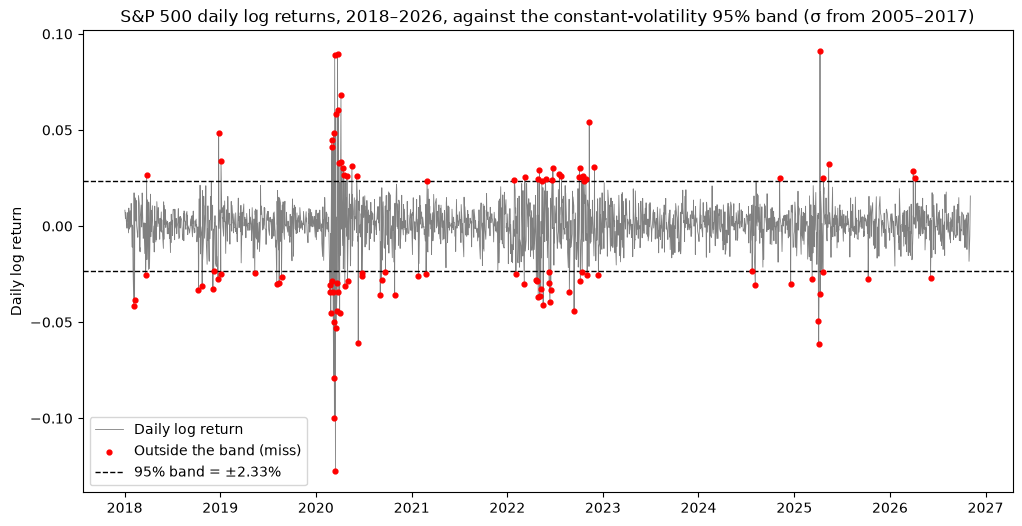

In [4]:
window = test_log_returns
miss = window.abs() > band

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(window.index, window.values, lw=0.6, color="grey", label="Daily log return")
ax.scatter(window.index[miss], window[miss], color="red", s=12, zorder=3,
           label="Outside the band (miss)")
ax.axhline(band, color="black", ls="--", lw=1, label=f"95% band = ±{band:.2%}")
ax.axhline(-band, color="black", ls="--", lw=1)
ax.set_title("S&P 500 daily log returns, 2018–2026, against the constant-volatility 95% band (σ from 2005–2017)", size=12)
ax.set_ylabel("Daily log return")
ax.legend(loc="lower left")

plt.show()

The single volatility above is an average over the whole calibration period. Measured year by year, volatility changes a great deal:

In [5]:
yearly_vol = fit_log_returns.groupby(fit_log_returns.index.year).std() * np.sqrt(252)
yearly_vol.to_frame("Annualised volatility").style.format("{:.1%}")

,Annualised volatility
Date,
2005,10.3%
2006,10.0%
2007,16.0%
2008,41.0%
2009,27.3%
2010,18.1%
2011,23.4%
2012,12.8%
2013,11.1%


Annualised volatility ranges from 6.7% (2017) to 41.0% (2008) within the calibration period alone. The single estimate of 18.9% describes none of these regimes well: the constant band is too wide in calm years and far too narrow in turbulent ones. This is visible in the band diagram above, where the misses are packed into the 2020 crash, with very few in the calmer years around it.

Volatility therefore has to be estimated in a way that **changes over time**, following the market from calm to turbulent periods and back. The next section introduces three such models, each a refinement of the last: rolling-window GBM, EWMA and GARCH(1,1).

## 2. Four volatility models

All four models share the same structure for the daily log return:
$$
r_t = \sigma_t\, z_t, \qquad z_t \sim N(0,1),
$$
and differ **only** in how the daily volatility $\sigma_t$ is estimated. Each model is written as a function that takes the calibration returns and the test returns and returns a series of daily $\sigma_t$, one for each test day. To avoid look-ahead, $\sigma_t$ only ever uses returns up to day $t-1$. The model **parameters** are fixed on 2005–2017; the **volatility** $\sigma_t$ is then updated day by day through the test period.

### From volatility to band
As discussed, all the models in this section produces a daily volatility $\sigma_t$ for each test day. A shared helper turns any $\sigma_t$ into the corresponding band, exactly as in Section 1, but now with a volatility that may change from day to day:
$$
\big[-z\,\sigma_t,\; +z\,\sigma_t\big],
$$
where $z$ is the standard normal quantile at $1 - (1-L)/2$ for coverage level $L$. For $L = 0.95$, $z \approx 1.96$.

In [6]:
def sigma_to_band(sigma,level =0.95):
    """Two-sided band (lower, upper) = (-z*sigma, +z*sigma) for daily log returns, with z the
    N(0,1) quantile at 1 - (1 - level)/2 (z ≈ 1.96 for level = 0.95). `level` is the coverage.
    Works for a single sigma or a pd.Series of sigma_t."""
    q = 1 - (1-level)/2          ## upper limit leaves (1 - level)/2 in the right tail, so it is the q-quantile of N(0, 1) 
    lower = -norm.ppf(q)*sigma
    upper = norm.ppf(q)*sigma
    return (lower,upper)

### Model 1: Constant-volatility GBM
The benchmark from Section 1: one daily volatility, the standard deviation of the 2005–2017 returns, used unchanged on every test day:
$$
\sigma_t = s \quad \text{for all } t \tag{1}.
$$

In [7]:
def const_gbm(fit_returns, test_returns):
    """Constant-volatility GBM: daily sigma = std of the fit-period log returns,
    the same on every test date. Returns a pd.Series indexed like test_returns."""
    return pd.Series(fit_returns.std(), index=test_returns.index)

### Model 2: Rolling-window GBM
Volatility is re-estimated every day from the previous $m$ daily returns, each with the same weight $1/m$ (older returns get no weight):
$$
\sigma_t^2 = \frac{1}{m}\sum_{i=1}^{m} r_{t-i}^2 \tag{2} .
$$
(In the code we use the sample standard deviation of the window, which also subtracts the window's mean and divides by $m-1$; for $m = 160$ the difference is negligible.) The window length $m$ is chosen on the calibration period in Section 3.

In [8]:
def rolling_gbm(fit_returns,test_returns,m):
    """Rolling-window GBM: daily sigma for each test date = std of the m returns
    strictly before it (no look-ahead). Returns a pd.Series indexed like test_returns."""
    rolling_returns = pd.concat([fit_returns.iloc[-m:],test_returns],axis=0)
    rolling_returns = rolling_returns.rolling(m).std()

    # Shift down one day: the value at date t now comes from the window ending at t-1,
    # so day t's own return never enters its own sigma (no look-ahead)
    rolling_returns = rolling_returns.shift(1)

    return pd.Series(rolling_returns,index=test_returns.index)

### Model 3: EWMA
Instead of equal weights $1/m$ that drop to zero after $m$ days, like in Eq. (2), EWMA gives the return $i$ days ago the weight $(1-\lambda)\lambda^{i-1}$, which decays gradually:
$$
\sigma_t^2 = (1-\lambda)\sum_{i=1}^{\infty} \lambda^{i-1}\, r_{t-i}^2 ,
$$
which reduces to the recursion
$$
\sigma_t^2 = \lambda\,\sigma_{t-1}^2 + (1-\lambda)\, r_{t-1}^2 \tag{3}.
$$

$\lambda$ is called the *decay factor*.

In [9]:
def ewma(fit_returns,test_returns,lam=0.94):
    """EWMA volatility: sigma2_t = lam * sigma2_{t-1} + (1 - lam) * r_{t-1}^2, using only
    returns before t (no look-ahead). Starts from the fit-period variance on the first
    test day (no warm-up). Returns daily sigma as a pd.Series indexed like test_returns."""
    var0 = fit_returns.var()
    var=[var0]
    for r in test_returns:
        var.append((1-lam)*r**2 + lam*var[-1])
    return pd.Series(np.sqrt(var[:-1]),index=test_returns.index)

### Model 4: GARCH(1,1)
GARCH generalises the EWMA recursion (3) in two ways:

1. The two weights $1-\lambda$ (on yesterday's squared return) and $\lambda$ (on yesterday's variance) are replaced by two **separate** parameters, $\alpha$ and $\beta$.
2. A constant term $\omega$ is added, which **anchors** the variance to a long-run level.

$$
\sigma_t^2 = \omega + \alpha\, r_{t-1}^2 + \beta\, \sigma_{t-1}^2 , \qquad \omega > 0,\ \ \alpha, \beta \ge 0,\ \ \alpha + \beta < 1 . \tag{4}
$$

The long-run (anchor) variance is
$$
V_L = \frac{\omega}{1-\alpha-\beta} . \tag{5}
$$
After a shock, the variance is expected to drift back towards $V_L$ (*mean reversion*). Writing $\gamma = 1 - \alpha - \beta$, so that $\omega = \gamma V_L$, the recursion (3) becomes a weighted average of three terms whose weights sum to 1:
$$
\sigma_t^2 = \gamma\, V_L + \alpha\, r_{t-1}^2 + \beta\, \sigma_{t-1}^2 .
$$
EWMA is the special case $\gamma = 0$ ($\omega = 0$, $\alpha + \beta = 1$), which has no long-run level.

In [10]:
def garch_sigma(fit_returns,test_returns,omega,alpha,beta):
    """GARCH(1,1) volatility: sigma2_t = omega + alpha * r_{t-1}^2 + beta * sigma2_{t-1}, with
    parameters fixed (estimated on the fit period), using only returns before t (no look-ahead).
    Starts from the fit-period variance on the first test day (no warm-up).
    Returns daily sigma as a pd.Series indexed like test_returns."""
    var0 = fit_returns.var()
    var=[var0]
    for r in test_returns:
        var.append(omega+alpha*r**2 + beta*var[-1])
    return pd.Series(np.sqrt(var[:-1]),index=test_returns.index)

## 3. Choosing the parameters

Each model has parameters that are fixed **on the calibration period (2005–2017) only**, before the test period is used. The test period then serves as a genuine out-of-sample check: nothing in the models is tuned on it.

### 3.1 Constant GBM
The only parameter is the daily volatility, estimated in Section 1 as the standard deviation of the 2005–2017 daily log returns (Eq. (1)): $s \approx 0.0119$, i.e. about 18.9% a year.

### 3.2 Rolling GBM: choosing the window length $m$
A short window reacts quickly to new shocks but is noisy; a long window is smooth but slow, and stays high long after a shock has passed. To choose $m$ using the calibration period only, we treat 2005–2006 as the starting window and 2007–2017 as an evaluation period. For each candidate $m$ between 20 and 480 trading days, we compute the rolling-window band on 2007–2017 and record the share of days on which the return falls outside it (the miss rate). A well-calibrated 95% band should give a miss rate close to 5%.

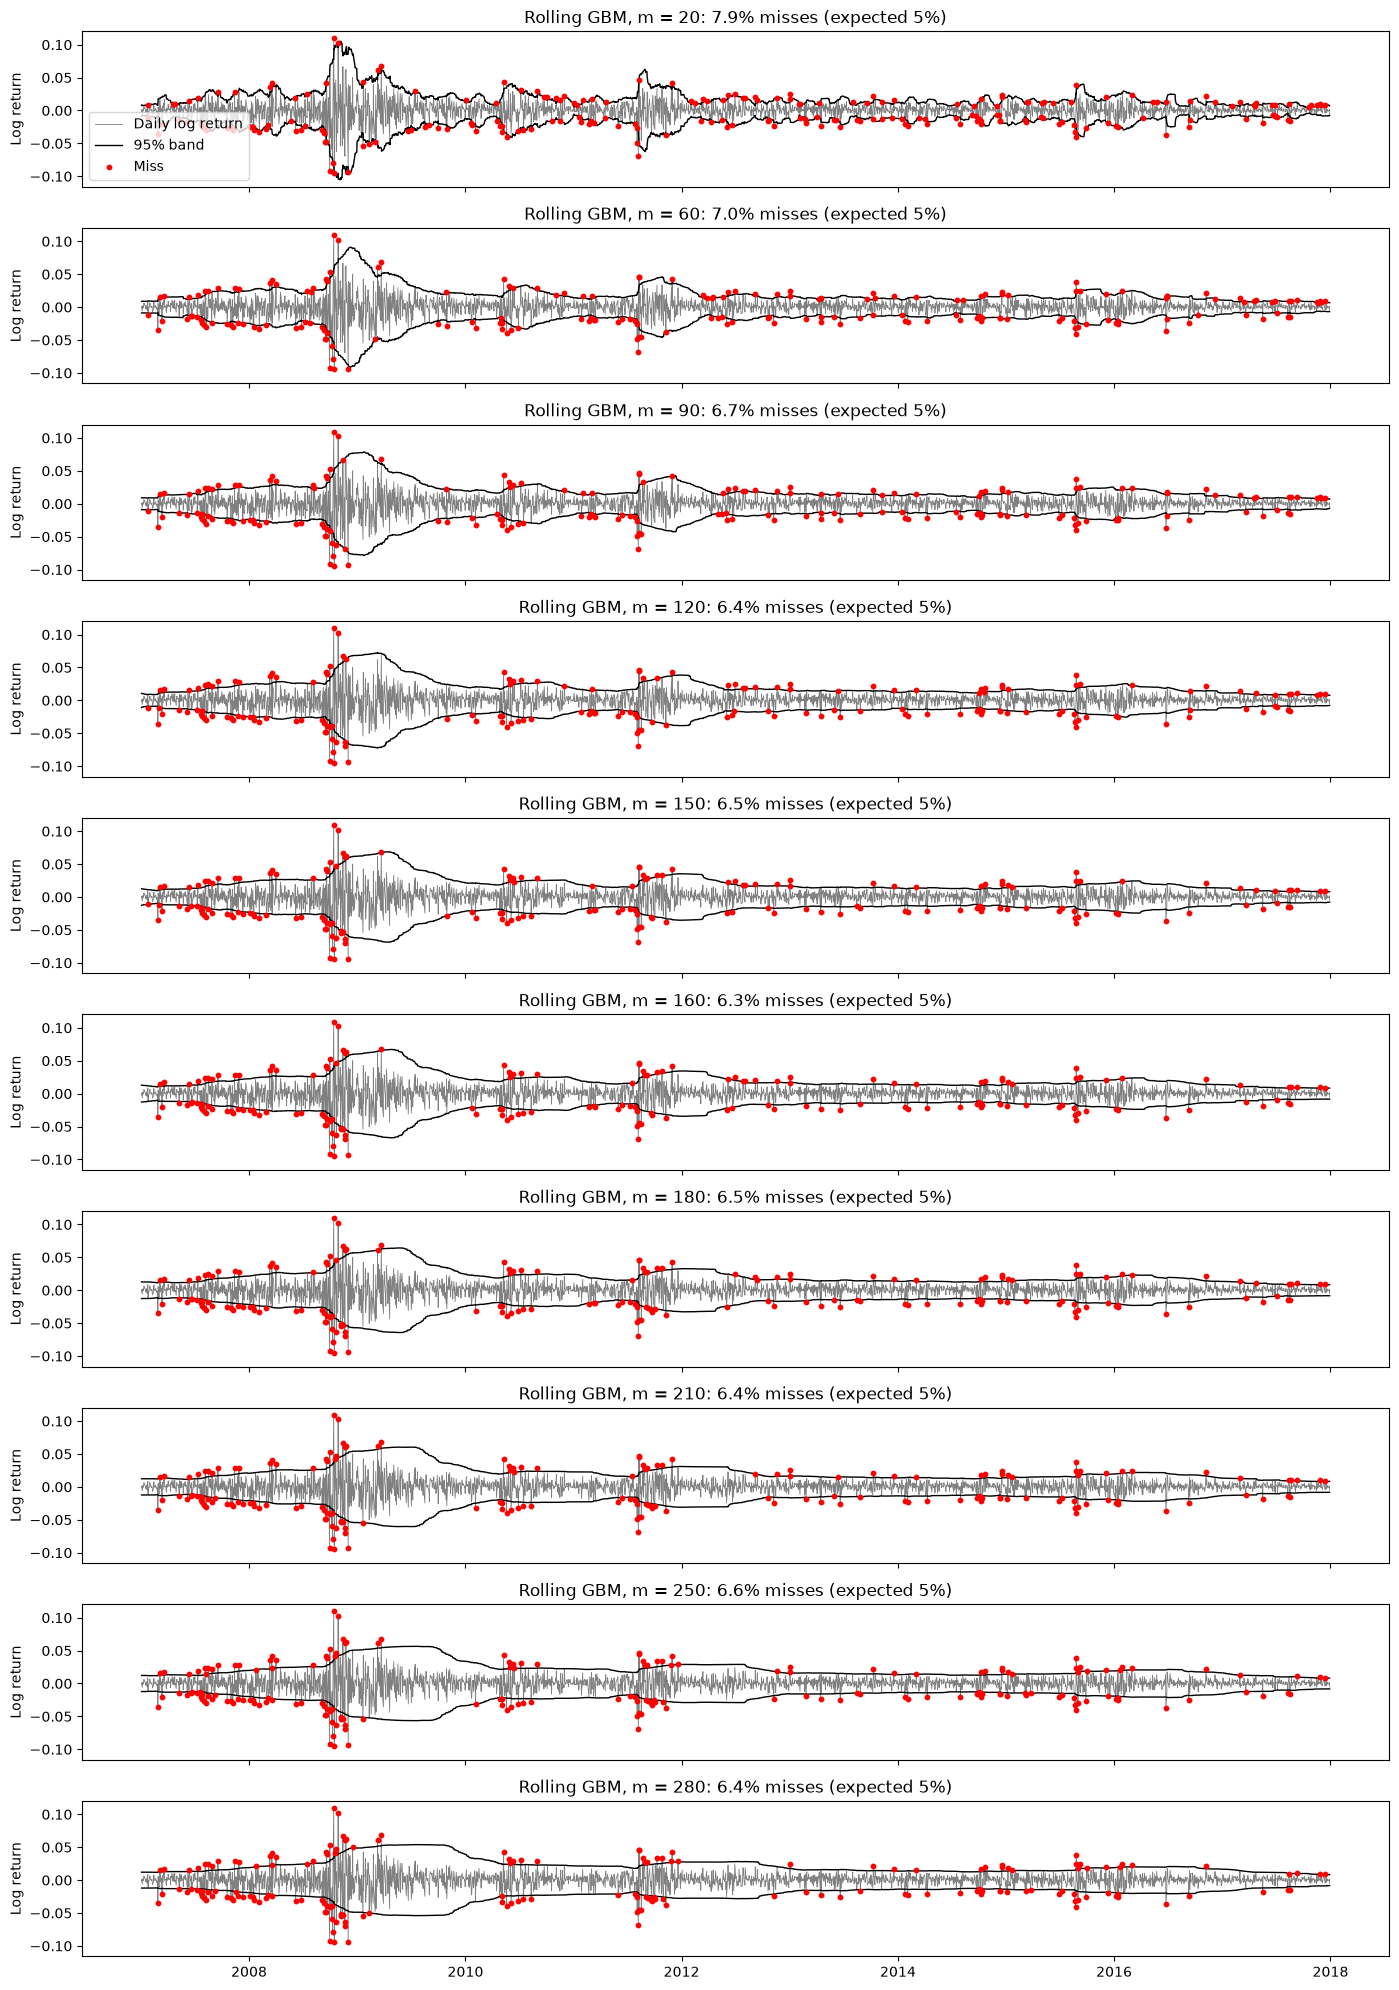

In [11]:
M = [20, 60, 90, 120, 150, 160, 180, 210, 250]
early = fit_log_returns.loc[:'2006']           # fills the first window
window = fit_log_returns.loc['2007':'2017']    # evaluation period (still inside the fit period)

results = []
for m in M:
    sigma = rolling_gbm(early, window, m)
    lower, upper = sigma_to_band(sigma)
    miss = window.abs() > upper

    # clustering: share of misses that come the day after another miss
    after_miss = miss & miss.shift(1, fill_value=False)
    share_clustered = after_miss.sum() / miss.sum()

    results.append({"m": m,
                    "miss_rate": miss.mean(),
                    "n_misses": miss.sum(),
                    "share_after_a_miss": share_clustered})

results = pd.DataFrame(results).set_index("m")
results


show = [20, 60, 90, 120, 150, 160, 180, 210, 250,280]
fig, axes = plt.subplots(len(show), 1, figsize=(14, 20), sharex=True, sharey=True)

for ax, m in zip(axes, show):
    sigma = rolling_gbm(early, window, m)
    lower, upper = sigma_to_band(sigma)
    miss = window.abs() > upper

    ax.plot(window.index, window.values, lw=0.6, color='grey', label='Daily log return')
    ax.plot(upper.index, upper.values, color='black', lw=1, label='95% band')
    ax.plot(lower.index, lower.values, color='black', lw=1)
    ax.scatter(window.index[miss], window[miss], color='red', s=10, zorder=3, label='Miss')
    ax.set_title(f"Rolling GBM, m = {m}: {miss.mean():.1%} misses (expected 5%)")
    ax.set_ylabel("Log return")

axes[0].legend(loc='lower left')
plt.tight_layout()
plt.show()


The miss rate falls steeply for short windows and is roughly flat between about 120 and 360 days (within about ±0.5 percentage points, the size of the sampling noise), rising again for very long windows. The lowest miss rate is at **$m = 160$** (6.3%), which we use from here on. This lies within the 90–180-day range suggested by Hull. All windows have miss rates above 5%, an early sign that the normal distribution understates the frequency of large moves.

### 3.3 EWMA: the decay factor $\lambda$
We use $\lambda = 0.94$, the value recommended for daily data by RiskMetrics (as reported in Hull), chosen there to work well across many assets. It is fixed rather than estimated, so EWMA serves as an industry benchmark that requires no fitting. With $\lambda = 0.94$, yesterday's squared return carries weight $1-\lambda = 0.06$, and the influence of a shock halves after about 11 trading days ($0.94^{n} = 0.5$).

### 3.4 GARCH(1,1): estimating $\omega$, $\alpha$, $\beta$
The three parameters of Eq. (5) are estimated by **maximum likelihood** on the calibration period: we choose the values of $\omega$, $\alpha$ and $\beta$ under which the observed 2005–2017 returns are most likely, assuming normal shocks. We use the `arch` package for the estimation (with returns scaled to percent for numerical stability, and $\omega$ converted back to decimal units).

In [12]:
def fit_garch(fit_returns):
    res = arch_model(fit_returns*100,mean='Zero',vol = 'GARCH', p=1,q=1, dist='normal').fit(disp='off')
    return (res.params['omega']/10**4,res.params['alpha[1]'],res.params['beta[1]'])

In [13]:
omega, alpha, beta = fit_garch(fit_log_returns)

persistence = alpha + beta
half_life = np.log(0.5) / np.log(persistence)       # trading days for a shock to halve
sigma_L = np.sqrt(omega / (1 - persistence))         # long-run daily volatility, from V_L

garch_params = pd.Series({
    "omega": omega,
    "alpha": alpha,
    "beta": beta,
    "alpha + beta (persistence)": persistence,
    "half-life (trading days)": half_life,
    "long-run daily volatility": sigma_L,
    "long-run annual volatility": sigma_L * np.sqrt(252),
})
garch_params.round(6)

omega                          0.000002
alpha                          0.102693
beta                           0.879631
alpha + beta (persistence)     0.982323
half-life (trading days)      38.864402
long-run daily volatility      0.010141
long-run annual volatility     0.160990
dtype: float64

**Reading the fitted parameters:**
- **Persistence, $\alpha + \beta \approx 0.982$.** Volatility shocks last a long time but do fade, because $\alpha + \beta < 1$ (mean reversion).
- **Half-life ≈ 39 trading days.** After a shock, the extra volatility is half gone in about two months. For EWMA ($\lambda = 0.94$) it is about 11 days.
- **Reaction, $\alpha \approx 0.103$.** This is the weight on yesterday's squared return. It is larger than EWMA's $1 - \lambda = 0.06$, so GARCH reacts more strongly to a single large move.
- **Long-run volatility, $\sqrt{V_L} \approx  $ 1.01% per day.** This is the level GARCH pulls volatility back towards. It is close to the sample volatility of 1.19% per day, as expected.

### 3.5 Summary: all settings fixed on 2005–2017

| Model | Parameter(s) | Value | How it was set |
|---|---|---|---|
| Constant GBM | daily volatility $s$ | 0.0119 | standard deviation of 2005–2017 returns |
| Rolling GBM | window length $m$ | 160 days | lowest miss rate on 2007–2017 |
| EWMA | decay factor $\lambda$ | 0.94 | RiskMetrics convention (fixed) |
| GARCH(1,1) | $\omega, \alpha, \beta$ | $1.8\times10^{-6}$, 0.103, 0.880 | maximum likelihood on 2005–2017 |

None of these settings uses any data from the test period. 

## 4. Backtest on the test period (2018 onwards)

With all settings fixed on 2005–2017, each model is now run forward through the test period. For each test day $t$, the model's volatility $\sigma_t$ uses only returns up to day $t-1$; the band is $\pm 1.96\,\sigma_t$ (Eq. (2)); and day $t$ is recorded as a **miss** if the actual return $r_t$ falls outside it. This gives one hit sequence per model.

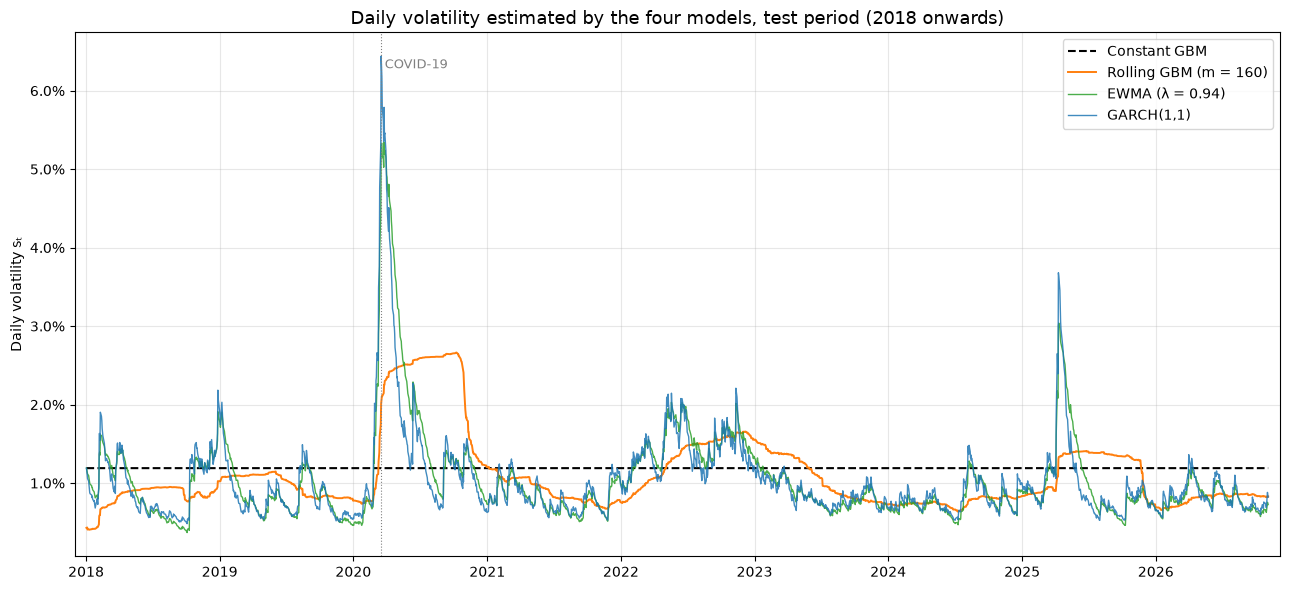

In [14]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(const_gbm(fit_log_returns, test_log_returns),
        color='black', lw=1.5, ls='--', label='Constant GBM')
ax.plot(rolling_gbm(fit_log_returns, test_log_returns, 160),
        color='tab:orange', lw=1.4, label='Rolling GBM (m = 160)')
ax.plot(ewma(fit_log_returns, test_log_returns),
        color='tab:green', lw=1.0, alpha=0.85, label='EWMA (λ = 0.94)')
ax.plot(garch_sigma(fit_log_returns, test_log_returns, omega, alpha, beta),
        color='tab:blue', lw=1.0, alpha=0.85, label='GARCH(1,1)')

# mark the main shocks in the test period
for date, label in [("2020-03-16", "COVID-19")]:
    ax.axvline(pd.Timestamp(date), color='grey', lw=0.8, ls=':')
    ax.text(pd.Timestamp(date), ax.get_ylim()[1] * 0.95, f" {label}",
            color='grey', fontsize=9, va='top')

ax.set_title("Daily volatility estimated by the four models, test period (2018 onwards)", fontsize=13)
ax.set_ylabel("Daily volatility sₜ")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))   # 0.02 shown as 2%
ax.grid(alpha=0.3)
ax.legend(loc='upper right')
ax.margins(x=0.01)

plt.tight_layout()
plt.show()

Constant GBM is a flat line. Rolling GBM rises and falls slowly, with sudden drops when a shock leaves its 160-day window. EWMA and GARCH react within days of each shock and move closely together; GARCH reaches higher peaks (its $\alpha$ is larger) and falls back faster afterwards (mean reversion towards its long-run level).

In [15]:
sigmas={}
sigmas["Constant GBM"] = const_gbm(fit_log_returns,test_log_returns)
sigmas["Rolling GBM with m = 160"] = rolling_gbm(fit_log_returns,test_log_returns,160)
sigmas["EWMA with λ = 0.94"] = ewma(fit_log_returns,test_log_returns)
sigmas["GARCH(1,1)"] = garch_sigma(fit_log_returns,test_log_returns,omega,alpha,beta)

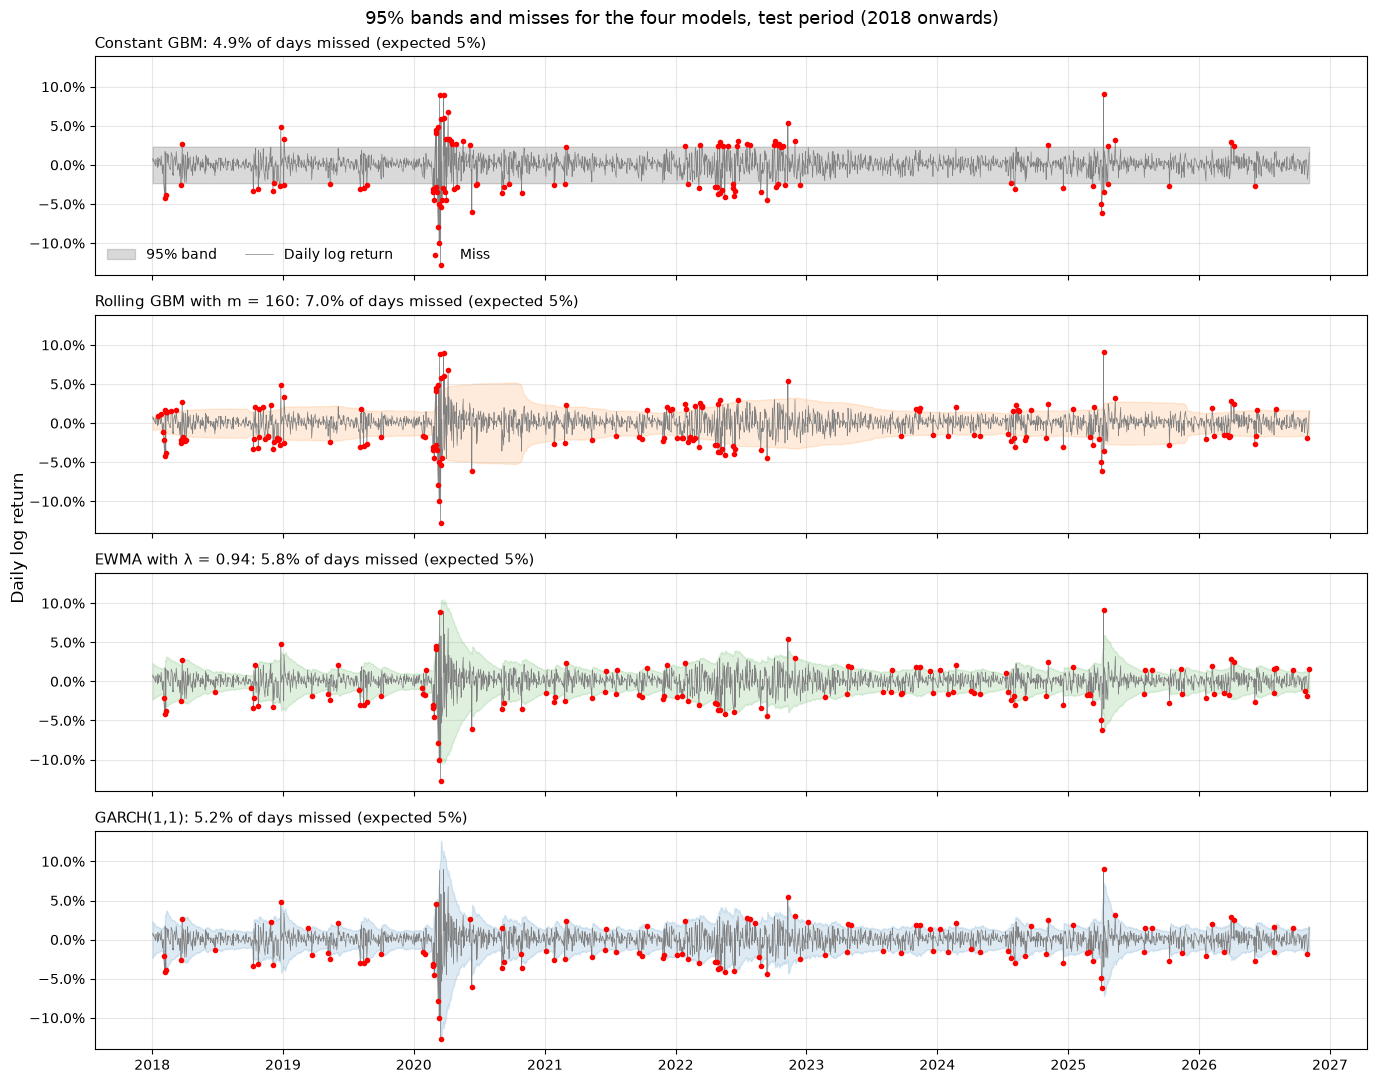

In [16]:
colours = ['black', 'tab:orange', 'tab:green', 'tab:blue']   # same colours as the volatility plot

hits=[]
fig, axes = plt.subplots(len(sigmas), 1, figsize=(14, 11), sharex=True, sharey=True)
for ax,(name,sigma),colour in zip(axes,sigmas.items(),colours):
    lower,upper = sigma_to_band(sigma)
    miss=test_log_returns.abs()>upper

    hits.append(miss)

    # shaded band, returns, and misses
    ax.fill_between(upper.index, lower.values, upper.values, color=colour, alpha=0.15, label='95% band')
    ax.plot(test_log_returns.index, test_log_returns.values, lw=0.5, color='grey', label='Daily log return')
    ax.scatter(test_log_returns.index[miss], test_log_returns[miss], color='red', s=9, zorder=3, label='Miss')

    ax.set_title(f"{name}: {miss.mean():.1%} of days missed (expected 5%)", loc='left', fontsize=11)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha=0.3)

axes[0].legend(loc='lower left', frameon=False, ncol=3)
fig.supylabel("Daily log return")
fig.suptitle("95% bands and misses for the four models, test period (2018 onwards)", fontsize=13)
plt.tight_layout()

**Miss rates (expected 5%):** constant GBM 4.9%, rolling GBM 7.0%, EWMA 5.7%, GARCH 5.2%.

The numbers alone would suggest constant GBM is the best model. The plot shows why that is misleading: its misses are packed into a few turbulent periods (March 2020, 2022, April 2025), with almost none in calm years, because its band has the same width every day. Rolling GBM adapts, but slowly, and has the most misses. EWMA and GARCH still miss the first days of each shock, but their bands widen within days, so their misses are spread much more evenly over time. Section 5 tests both the number of misses and their timing formally.

## 5. Testing the bands

A reliable 95% band should be missed on about 5% of days, **at random times**. For each model, the hit sequence $I_t$ ($I_t = 1$ if day $t$ is a miss, $0$ otherwise) should therefore behave like independent draws with a 5% chance of a miss. Two standard backtests check the two parts of this, each as a likelihood ratio test:

**Kupiec's test (1995): the number of misses.**
$H_0$: the probability of a miss is $p = 0.05$. With $n$ test days and $x$ misses, the observed rate is $\hat p = x/n$, and
$$
LR_{\text{Kupiec}} = -2 \ln \frac{(1-p)^{n-x}\, p^{x}}{(1-\hat p)^{n-x}\, \hat p^{x}} \;\sim\; \chi^2_1 .
$$
It rejects both too many misses (band too narrow) and too few (band too wide), but it cannot see *when* the misses happen.

**Christoffersen's test (1998): independence of misses.**
Counting the transitions between consecutive days ($n_{00}, n_{01}, n_{10}, n_{11}$, where $n_{ij}$ is the number of days in state $j$ following a day in state $i$), we estimate the probability of a miss after a day without one, $\hat\pi_{01} = n_{01}/(n_{00}+n_{01})$, and after a miss, $\hat\pi_{11} = n_{11}/(n_{10}+n_{11})$.
$H_0$: misses are independent, i.e. $\pi_{01} = \pi_{11}$. The likelihood ratio comparing "one miss probability for all days" with "a miss probability that depends on yesterday" is again $\sim \chi^2_1$.

In both tests we reject $H_0$ at the 5% level if the p-value is below 0.05 (equivalently, $LR > 3.84$). Not rejecting $H_0$ means the data gives no significant evidence against the model; it does not prove the model correct.

In [17]:
def kupiec_test(hits, coverage=0.95, alpha=0.05):
    """
    Kupiec (1995) proportion-of-failures test.

    H0: the probability of a miss is exactly p = 1 - coverage.

    Parameters
    ----------
    hits : pd.Series of bool
        True on days the return fell outside the band. Any period or slice.
    coverage : float, default 0.95
        Coverage the band promises (gives p = 1 - coverage under H0).
    alpha : float, default 0.05
        Significance level of the test (reject if p-value < alpha).

    Returns
    -------
    dict with n, x, p_hat, LR, p_value, reject
    """

    n=len(hits)
    x=hits.sum()
    p=1-coverage
    p_hat = x/n
    LR = -2*(xlogy(x,p) + xlogy((n-x),1-p) - xlogy(x,p_hat) - xlogy((n-x),1-p_hat))
    p_value = chi2.sf(LR,df=1)
    reject = p_value < alpha
    return  {"n":n,"x":x,"p_hat":p_hat,"LR":LR, "p_value" :p_value, "reject":reject}  
# your body here: n, x, p_hat → log-likelihoods → LR → p-value → dict

In [18]:
def kupiec_table(hits, names, period=None, **kwargs):
    """Run kupiec_test on every model for one period; return one row per model."""
    rows = {}
    for name, h in zip(names, hits):
        h_sel = h if period is None else h.loc[period]   # whole test period, or a slice
        rows[name] = kupiec_test(h_sel, **kwargs)
    return pd.DataFrame(rows).T

In [19]:
def christoffersen_test(hits, alpha=0.05):
    """
    Christoffersen (1998) independence test.

    H0: misses are independent, i.e. the probability of a miss today does not
    depend on whether yesterday was a miss (pi_01 = pi_11).

    Parameters
    ----------
    hits : pd.Series of bool
        True on days the return fell outside the band. Any period or slice.
    alpha : float, default 0.05
        Significance level (reject if p-value < alpha).

    Returns
    -------
    dict with n00, n01, n10, n11, pi_01, pi_11, LR, p_value, reject
    """
    h=np.asarray(hits,dtype=int)
    prev=h[:-1]
    curr=h[1:]
    n00=((prev==0) & (curr==0)).sum()
    n01=((prev==0) & (curr==1)).sum()
    n10=((prev==1) & (curr==0)).sum()
    n11=((prev==1) & (curr==1)).sum()
    pi_01 = n01/(n01+n00)
    pi_11 = n11/(n11+n10) if (n11+n10)>0 else 0
    pi = (n01+n11)/(n00+n11+n01+n10)
    LR = -2*(xlogy(n01+n11,pi)+xlogy(n00+n10,1-pi)-xlogy(n01,pi_01) -xlogy(n00,1-pi_01)-xlogy(n11,pi_11)-xlogy(n10,1-pi_11))
    p_value = chi2.sf(LR,df=1)
    reject = p_value<alpha

    return {"n00":n00, "n01":n01, "n10":n10,"n11":n11, "pi_01":pi_01, "pi_11":pi_11, "LR":LR, "p_value":p_value, "reject":reject}

In [20]:
def christoffersen_table(hits, names, period=None, **kwargs):
    """Run christoffersen_test on every model for one period; return one row per model."""
    rows = {}
    for name, h in zip(names, hits):
        h_sel = h if period is None else h.loc[period]   # whole test period, or a slice
        rows[name] = christoffersen_test(h_sel, **kwargs)
    return pd.DataFrame(rows).T

## 6. Results

### 6.1 Full test period (2018 onwards)

In [21]:
names = ["const_gbm","rolling_gbm","ewma","garch"]
kupiec_table(hits,names)

,n,x,p_hat,LR,p_value,reject
const_gbm,2223,109,0.049033,0.044047,0.833767,False
rolling_gbm,2223,156,0.070175,17.019623,0.000037,True
ewma,2223,128,0.05758,2.569105,0.108969,False
garch,2223,116,0.052182,0.219763,0.639221,False


In [22]:
christoffersen_table(hits,names)

,n00,n01,n10,n11,pi_01,pi_11,LR,p_value,reject
const_gbm,2031,82,82,27,0.038807,0.247706,54.120817,0.0,True
rolling_gbm,1947,119,119,37,0.057599,0.237179,48.313265,0.0,True
ewma,1979,116,115,12,0.05537,0.094488,2.889381,0.089165,False
garch,1997,109,109,7,0.051757,0.060345,0.15682,0.692101,False


**Kupiec (number of misses):** only rolling GBM is rejected (7.0% misses, p < 0.001). Constant GBM (4.9%), EWMA (5.8%) and GARCH (5.2%) are consistent with 5%.

**Christoffersen (independence):** constant GBM and rolling GBM are rejected decisively (p < 0.001). For constant GBM, a miss is followed by another miss on 24.8% of days, against 3.9% after a day without a miss; rolling GBM shows the same pattern (24.7% against 5.9%). EWMA shows mild clustering that is not significant at the 5% level (p ≈ 0.09); GARCH shows essentially none (6.0% against 5.2%, p ≈ 0.69).

So constant GBM passes the count-based test but fails the independence test: its misses are the right number but arrive in clusters.

In [23]:
kup = kupiec_table(hits, names)
chr_ = christoffersen_table(hits, names)

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

summary = pd.DataFrame({
    "Miss rate": kup["p_hat"].astype(float).map("{:.1%}".format),
    "Kupiec p": kup["p_value"].astype(float).map(fmt_p),
    "Right number of misses?": kup["reject"].map({False: "Yes", True: "No"}),
    "P(miss | no miss yesterday)": chr_["pi_01"].astype(float).map("{:.1%}".format),
    "P(miss | miss yesterday)": chr_["pi_11"].astype(float).map("{:.1%}".format),
    "Christoffersen p": chr_["p_value"].astype(float).map(fmt_p),
    "Misses independent?": chr_["reject"].map({False: "Yes", True: "No"}),
})
summary.index = ["Constant GBM", "Rolling GBM (m = 160)", "EWMA (λ = 0.94)", "GARCH(1,1)"]
summary

,Miss rate,Kupiec p,Right number of misses?,P(miss | no miss yesterday),P(miss | miss yesterday),Christoffersen p,Misses independent?
Constant GBM,4.9%,0.834,Yes,3.9%,24.8%,< 0.001,No
Rolling GBM (m = 160),7.0%,< 0.001,No,5.8%,23.7%,< 0.001,No
EWMA (λ = 0.94),5.8%,0.109,Yes,5.5%,9.4%,0.089,Yes
"GARCH(1,1)",5.2%,0.639,Yes,5.2%,6.0%,0.692,Yes


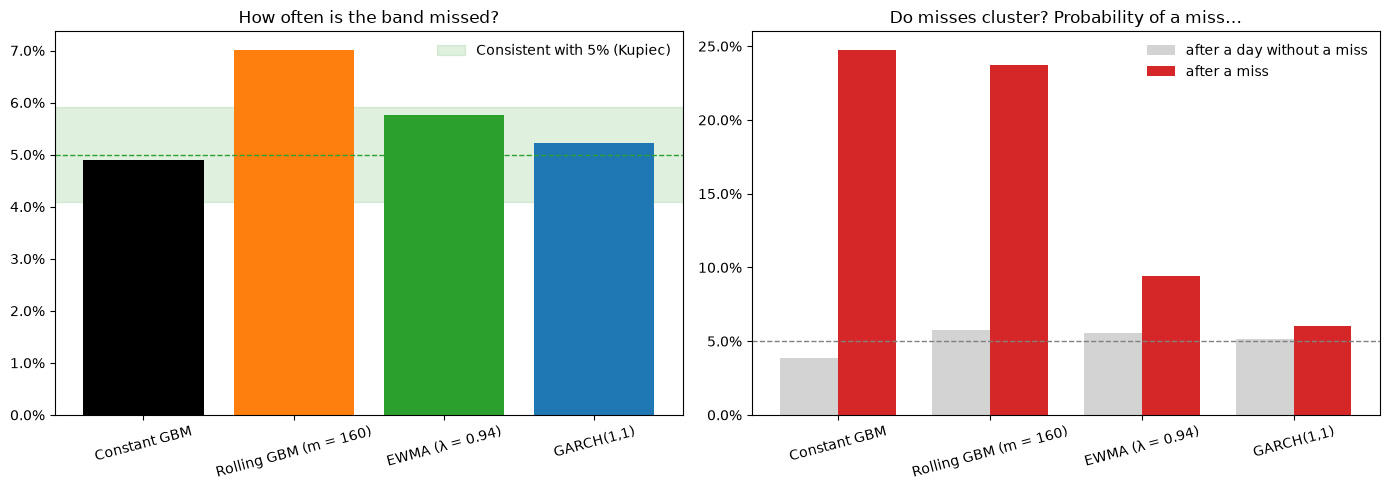

In [24]:
labels = summary.index
x = np.arange(len(labels))
n = int(kup["n"].iloc[0])
half = 1.96 * np.sqrt(0.05 * 0.95 / n)            # Kupiec "not rejected" zone, approx.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: miss rate against the zone Kupiec would accept
ax1.axhspan(0.05 - half, 0.05 + half, color="tab:green", alpha=0.15, label="Consistent with 5% (Kupiec)")
ax1.axhline(0.05, color="tab:green", ls="--", lw=1)
ax1.bar(x, kup["p_hat"].astype(float), color=["black", "tab:orange", "tab:green", "tab:blue"])
ax1.set_xticks(x, labels, rotation=15)
ax1.yaxis.set_major_formatter(PercentFormatter(1.0))
ax1.set_title("How often is the band missed?")
ax1.legend(frameon=False)

# Right: miss probability after a calm day vs after a miss
w = 0.38
ax2.bar(x - w/2, chr_["pi_01"].astype(float), w, color="lightgrey", label="after a day without a miss")
ax2.bar(x + w/2, chr_["pi_11"].astype(float), w, color="tab:red", label="after a miss")
ax2.axhline(0.05, color="grey", ls="--", lw=1)
ax2.set_xticks(x, labels, rotation=15)
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set_title("Do misses cluster? Probability of a miss…")
ax2.legend(frameon=False)

plt.tight_layout()
plt.show()

### 6.2 A crisis year and a calm year

Over the full test period, constant GBM's miss rate (4.9%) looks almost perfect. To see what lies behind that number, we repeat Kupiec's test for two contrasting single years: **2020**, the year of the COVID-19 crash, and **2023**, the calmest year of the test period. With only about 250 days in a year, the test is less precise, so the range of miss rates consistent with 5% is wider (roughly 2.3% to 7.7%, shaded grey below).

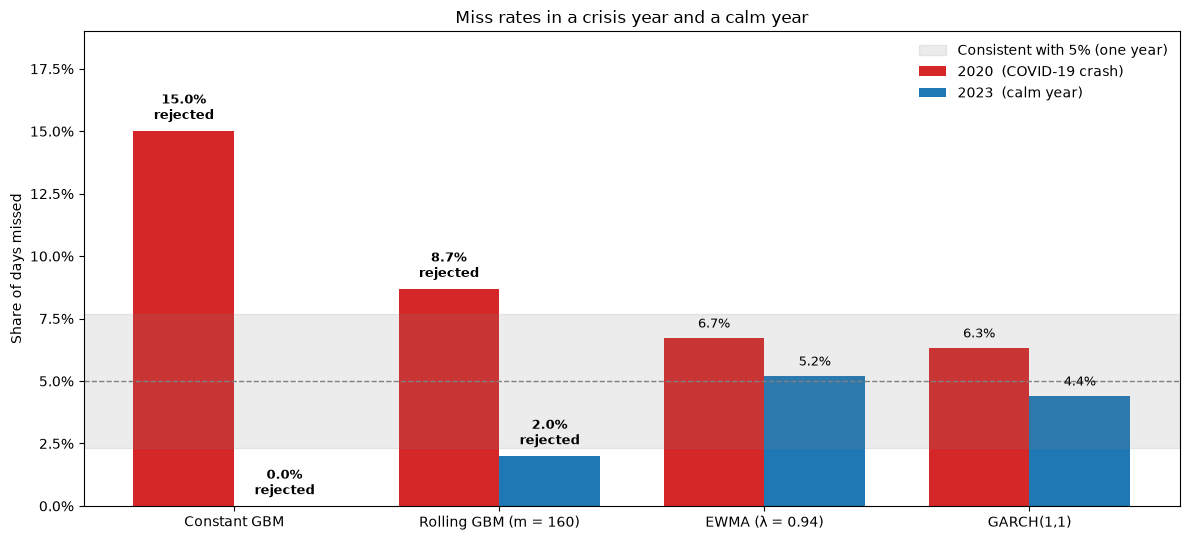

In [26]:
years = ["2020", "2023"]
year_colours = {"2020": "tab:red", "2023": "tab:blue"}
labels = ["Constant GBM", "Rolling GBM (m = 160)", "EWMA (λ = 0.94)", "GARCH(1,1)"]
x = np.arange(len(labels))
w = 0.38

fig, ax = plt.subplots(figsize=(12, 5.5))

for k, year in enumerate(years):
    tab = kupiec_table(hits, names, year)
    rates = tab["p_hat"].astype(float).values
    rejected = tab["reject"].astype(bool).values
    bars = ax.bar(x + (k - 0.5) * w, rates, w, color=year_colours[year],
                  label=f"{year}  ({'COVID-19 crash' if year == '2020' else 'calm year'})")
    # mark the models Kupiec rejects in that year
    for bar, rate, rej in zip(bars, rates, rejected):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.003,
                f"{rate:.1%}" + ("\nrejected" if rej else ""),
                ha="center", va="bottom", fontsize=9,
                fontweight="bold" if rej else "normal")

# zone Kupiec accepts for about 252 days
n_year = 252
half = 1.96 * np.sqrt(0.05 * 0.95 / n_year)
ax.axhspan(0.05 - half, 0.05 + half, color="grey", alpha=0.15, label="Consistent with 5% (one year)")
ax.axhline(0.05, color="grey", ls="--", lw=1)

ax.set_xticks(x, labels)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Share of days missed")
ax.set_title("Miss rates in a crisis year and a calm year")
ax.set_ylim(0, 0.19)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

The two years reveal what the full-period figure hides:

- **Constant GBM fails in both directions.** In 2020 it is missed on 15.0% of days, three times the promised rate (rejected: the band is far too narrow). In 2023 it is never missed (rejected: the band is far too wide). Its overall 4.9% is these two opposite errors averaging out, not evidence of a good model.
- **Rolling GBM** misses 8.7% of days in 2020 and 2.0% in 2023: it adapts, but too slowly to stay within the 5% range in either year.
- **EWMA and GARCH stay consistent with 5% in both years** (EWMA: 6.7% and 5.2%; GARCH: 6.3% and 4.4%). Their bands widen in the crisis and narrow in the calm year, so the miss rate stays close to the promised level whatever the market does.



#### The Upshot: 
The constant-volatility model gets the average right and the extremes wrong; GARCH and EWMA get both right. Over 2018–2026, constant GBM's band is missed on 4.9% of days, almost exactly the promised 5%, yet it is missed on 15.0% of days in the 2020 crash and on none in calm 2023, and its misses arrive in clusters. EWMA and GARCH, which update volatility each day from the previous day's return, stay close to 5% in both years and pass both backtests.

## 7. Conclusions

**Question.** Can volatility models give reliable 95% bands for the S&P 500's next-day return, and how should volatility be estimated to make them reliable?

**Answer.** Yes, if volatility is updated each day from the previous day's return. Over 2018 onwards (2,223 test days, all settings fixed on 2005–2017):

| Model | Miss rate | Right number of misses? (Kupiec) | Misses independent? (Christoffersen) |
|---|---|---|---|
| Constant GBM | 4.9% | Yes (p = 0.83) | **No** (p < 0.001) |
| Rolling GBM (m = 160) | 7.0% | **No** (p < 0.001) | **No** (p < 0.001) |
| EWMA (λ = 0.94) | 5.8% | Yes (p = 0.11) | Yes, borderline (p = 0.09) |
| GARCH(1,1) | 5.2% | Yes (p = 0.64) | Yes (p = 0.69) |

**Main findings.**
1. **Getting the miss rate right is not the same as getting risk right.** Constant GBM has the most accurate overall miss rate, yet it fails in both regimes: 15.0% misses in 2020 (band far too narrow) and 0% in 2023 (band far too wide). The errors cancel over the full period, so the count-based test does not detect them; the independence test does: after a miss, its next day is a miss 24.8% of the time, against 3.9% after a day without one.
2. **Updating volatility slowly is not enough.** Rolling GBM adapts, but with a lag. It has too many misses (7.3%), and they cluster.
3. **Models that react to yesterday's shock pass both tests.** EWMA and GARCH widen their bands within days of a shock. They still miss the first days of a crash (they react to news; they do not predict it), but their misses do not accumulate, and both stay consistent with 5% in both 2020 and 2023.
4. **GARCH performs best, but EWMA is close.** GARCH passes both tests comfortably; EWMA shows mild clustering that is not statistically significant. For one-day bands, the fixed RiskMetrics rule ($\lambda = 0.94$) does nearly as well as a fitted model.

**Takeaway.** A risk model should be judged not only on how often its bands are breached, but on *when*. Evaluating it over a long period alone can hide exactly the failures that matter most: those during crises.

## Limitations and next steps

**Limitations**

- **Normal distribution.** All bands assume normally distributed shocks. Real returns have fatter tails: every rolling window tested on 2007–2017 was missed on more than 5% of days. At the 95% level the models cope; at 99%, normal-based bands would likely fail.
- **Two-sided bands.** Misses on the loss side and the gain side are counted together. Risk management mainly cares about losses, and large falls tend to be more frequent and more clustered than large rises.
- **Frozen parameters.** All settings are fixed once on 2005–2017 and used unchanged until 2026. In practice, models are re-estimated regularly; GARCH's long-run volatility, learned from 2005–2017, may be out of date by the end of the test period.
- **No warm-up for EWMA and GARCH.** Both start 2018 from the 2005–2017 variance rather than the very calm level of late 2017, which biases the first weeks of the test period, including the February 2018 shock.
- **One market, one split.** Results are for the S&P 500 with a single split at the end of 2017, and the test period contains only a handful of crises. Conclusions may differ for single stocks, other markets or other periods.
- **What the tests cannot see.** Kupiec only counts misses; Christoffersen only detects misses on consecutive days, not clusters spread over a few weeks. Both have little power on short windows such as a single year.
- **Size of misses ignored.** A miss of −2.5% and a miss of −12% count the same.
- **No industry benchmark.** Historical simulation, the method most widely used by banks, is not included.

**Next steps**

- **Student-t shocks** and a **99% band** check, to address fat tails.
- **Downside and upside misses separately**, and **GJR-GARCH**, which lets volatility react more to falls than to rises.
- **Periodic re-estimation** of the parameters, and a check of how stable $\omega$, $\alpha$ and $\beta$ are across regimes.
- **Expected Shortfall**, to account for the size of losses beyond the band.
- **Historical simulation** and filtered historical simulation as industry benchmarks.
- **Comparison with the VIX**, the market's own volatility forecast.
- **Another market** (e.g. the Nifty 50), to test whether the conclusions generalise.
- **An own implementation of GARCH maximum likelihood**, as a check on the `arch` package.

## References

**Books**
- Hull, J. C. *Options, Futures, and Other Derivatives.* Pearson. Chapters on estimating volatility from historical data, EWMA and GARCH volatility models, and back-testing Value at Risk.


**Papers**
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Engle, R. F. (2001). GARCH 101: The use of ARCH/GARCH models in applied econometrics. *Journal of Economic Perspectives*, 15(4), 157–168.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.

**Industry methodology**
- J.P. Morgan/Reuters (1996). *RiskMetrics: Technical Document*, 4th edition. New York. (Source of $\lambda = 0.94$ for daily data, as reported in Hull.)

**Data and software**
- S&P 500 index (^GSPC) daily prices from Yahoo Finance, downloaded with the `yfinance` Python package.
- Sheppard, K. `arch`: ARCH and other tools for financial econometrics in Python. https://github.com/bashtage/arch